# Stage 5 — Fine-tuning BERT as a regressor

**Goal.** Explore the BERT regression setup (target scaling, long-text strategy, early stopping on validation MAE) and its training curves.

Logic: `src/train_bert.py`. Training runs as a script (`python -m src.train_bert`), not in this notebook.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import utils

utils.set_seed()
print("SEED:", utils.SEED, "| device:", utils.get_device(), "| root:", utils.ROOT)

SEED: 42 | device: mps | root: /Users/michelle.li/Documents/HW_04_202602


## Setup

`src/train_bert.py` fine-tunes **distilbert-base-uncased** as a regressor:

- **Model and data.** `AutoModelForSequenceClassification(num_labels=1, problem_type="regression")`, trained on `train` and early-stopped on `val`.
- **Target.** `exp_year / 20` during training; predictions are multiplied back by 20 and clipped to [0, 20].
- **Loss.** MSE by default; `--loss huber` (δ = 0.05 in scaled units, i.e. 1 year) for Question 3.
- **Long texts.** `--strategy head` by default. No CV has more than 162 DistilBERT tokens (stage 4), so with `max_len = 256` nothing is truncated and every job date reaches the model; the run logs `cvs_losing_a_year = 0`. `head_tail` and `chunk_avg` are implemented for longer CVs (checked with `max_len = 64`: head loses a year in 405 of 600 val CVs, chunk_avg in 0).
- **Optimisation.** AdamW, lr 5e-5, weight decay 0.01, linear schedule with 10% warmup, gradient clipping at 1.0. Batch 8 with gradient accumulation 2 (effective batch 16), padded per batch.
- **Stopping and hardware.** At most 8 epochs, early stopping on validation MAE with patience 2. MPS, fp32 (`PYTORCH_ENABLE_MPS_FALLBACK=1`), seed 42.

Training runs as a script in the Terminal, not in this notebook:

```bash
python -m src.train_bert                    # main model: clean OCR text
python -m src.train_bert --variant raw      # Question 3
```

In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from src.evaluation import collect_val_metrics
from src.visualization import plot_training_curve

def bert_metrics(run):
    for subdir in ("bert", "bert_tests"):
        path = utils.METRICS_DIR / subdir / f"{run}.json"
        if path.exists():
            return json.loads(path.read_text())
    return None

main_run = bert_metrics("bert__clean")
if main_run is None:
    print("Full training not done yet: showing the 200-CV / 1-epoch quick test.")
    main_run = bert_metrics("quick_test")
pd.Series({**main_run["config"], "effective_batch_size": main_run["effective_batch_size"],
           "epochs_trained": main_run["epochs_trained"], "best_epoch": main_run["best_epoch"],
           "train_minutes": round(main_run["train_seconds"] / 60, 1),
           "seconds_per_epoch": round(main_run["seconds_per_epoch"], 1),
           "inference_ms_per_cv": round(1000 * main_run["inference_seconds_per_cv"], 1),
           **main_run["hardware"]}, name="value").to_frame()

,value
variant,clean
strategy,head
loss,mse
huber_delta,0.05
max_len,256
chunk_stride,64
lr,0.00005
weight_decay,0.01
warmup_ratio,0.1
batch_size,8


### Do the dates survive truncation?

Yes. The run reports, for train and validation, the longest CV in tokens, how many CVs are cut, and how many lose at least one year that the full text contains.

In [3]:
pd.DataFrame(main_run["truncation"]).T

,max_tokens,cvs_truncated,cvs_losing_a_year,windows_per_cv
train,160.0,0.0,0.0,1.0
val,157.0,0.0,0.0,1.0


## Training curve

**Why this chart.** The training loss shows whether the model is still learning; the validation MAE shows whether that learning generalises, and early stopping keeps the epoch where it is lowest. They are drawn in two panels because they have different units. The dashed lines are the validation MAE of the TF-IDF baseline and of the date rules, for reference.

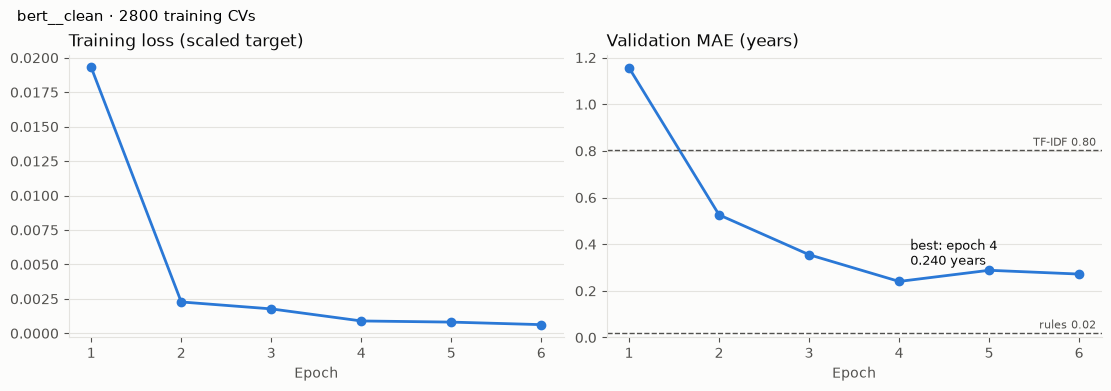

,epoch,train_loss,val_mae,val_rmse,val_acc_2,epoch_seconds,lr_end
0,1,0.0193,1.1561,1.5144,0.8233,131.3496,0.0
1,2,0.0023,0.5258,0.6435,1.0000,117.1532,0.0
2,3,0.0018,0.3550,0.4475,1.0000,110.5381,0.0
3,4,0.0009,0.2404,0.3256,1.0000,229.5892,0.0
4,5,0.0008,0.2882,0.4003,1.0000,178.4023,0.0
5,6,0.0006,0.2720,0.3379,1.0000,208.4665,0.0


In [4]:
history = pd.DataFrame(main_run["history"])
val = collect_val_metrics(("baselines",))
ref = val[val["variant"] == "clean"].set_index("model")["val_mae"]
fig = plot_training_curve(history, main_run["best_epoch"], {"TF-IDF": ref["tfidf"], "rules": ref["rules"]},
                          title=f"{main_run['run']} · {main_run['n_train']} training CVs")
plt.show()
history.round(4)

## Validation MAE: BERT vs the baselines

All models on the same validation CVs (the test set is still untouched). The table also covers the other text variants and losses once those runs exist.

In [5]:
val = collect_val_metrics(("baselines", "bert"))
display(val.pivot(index="model", columns="variant", values="val_mae").round(3))
val[val["variant"] == "clean"].sort_values("val_mae").round(4)

variant,clean,clean_dropped_lowconf,raw
model,,,
bert,0.240,NaN,0.402
embeddings,1.130,1.181,1.228
median,3.531,3.531,3.531
rules,0.021,0.034,0.021
tfidf,0.804,0.869,0.786


,model,variant,val_mae,val_rmse,val_acc_1,val_acc_2,val_acc_3,val_band_accuracy,val_band_macro_f1,val_r2,train_seconds,inference_seconds_per_cv
6,rules,clean,0.0209,0.0244,1.0000,1.0000,1.0000,0.9833,0.9848,1.0000,0.0000,0.0000
12,bert,clean,0.2404,0.3256,0.9933,1.0000,1.0000,0.9517,0.9548,0.9947,1017.3058,0.0074
9,tfidf,clean,0.8043,1.0618,0.6933,0.9383,0.9833,0.8850,0.8913,0.9432,1.4266,0.0004
0,embeddings,clean,1.1300,1.4881,0.5650,0.8667,0.9517,0.8233,0.8299,0.8885,9.2326,0.0034
3,median,clean,3.5313,4.5659,0.1633,0.3350,0.5283,0.2850,0.1109,-0.0499,0.0006,0.0000
